# Titanic: Naive Bayes

Train Naive Bayes, evaluate survival predictions, and save the results. Run cells from top to bottom. The other model notebook uses exactly the same preparation and passenger split.

Compare the original scikit-learn estimator with an explicit NumPy implementation.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay)

ROOT = Path.cwd()
if not (ROOT / "data" / "data_preparation.py").is_file():
    ROOT = ROOT.parent  # supports a kernel started in models/
sys.path.insert(0, str(ROOT))
from data.data_preparation import load_data, prepare_data

OUTPUT = ROOT / "data" / "output"
GRAPHS = OUTPUT / "graphs"
GRAPHS.mkdir(parents=True, exist_ok=True)

## 2. Inspect and prepare data

`data/data_preparation.py` loads the original input and the fixed split, fills missing values using training medians/modes, encodes training categories, and scales numeric features using training statistics only.

In [2]:
frame = load_data()
print("Input shape:", frame.shape)
print("Missing values:\n", frame.isna().sum())
print("Duplicate rows:", frame.duplicated().sum())
print("Survival counts:\n", frame.Survived.value_counts())
X_train, X_test, y_train, y_test = prepare_data()
print("Training records:", len(X_train), "| Test records:", len(X_test))
print("Prepared columns:", X_train.columns.tolist())

Input shape: (891, 12)
Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Duplicate rows: 0
Survival counts:
 Survived
0    549
1    342
Name: count, dtype: int64
Training records: 712 | Test records: 179
Prepared columns: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_2', 'Pclass_3', 'Sex_male', 'Embarked_Q', 'Embarked_S']


## 3. Train with scikit-learn

Gaussian Naive Bayes combines class priors with Gaussian feature likelihoods. It assumes conditional independence. Counts and encoded categories are not Gaussian, so this is an approximation.

In [3]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model_name = 'Naive Bayes'
file_stem = 'naive_bayes'
model.fit(X_train, y_train)
print(model_name, "training complete")

Naive Bayes training complete


## 4. Implement with NumPy

Estimate class priors and per-class Gaussian parameters, then combine log-likelihoods and normalize the probabilities.

In [4]:
class GaussianNaiveBayesNumPy:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        self.classes_, counts = np.unique(y, return_counts=True)
        self.priors_ = counts / len(y)
        self.epsilon_ = max(self.var_smoothing * X.var(axis=0).max(), np.finfo(float).eps)
        self.means_ = np.array([X[y == label].mean(axis=0) for label in self.classes_])
        self.variances_ = np.array([X[y == label].var(axis=0) for label in self.classes_])
        self.variances_ += self.epsilon_
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        log_scores = []
        for prior, mean, variance in zip(self.priors_, self.means_, self.variances_):
            log_density = -0.5 * (np.log(2 * np.pi * variance) + (X - mean) ** 2 / variance)
            log_scores.append(np.log(prior) + log_density.sum(axis=1))
        log_scores = np.column_stack(log_scores)
        log_scores -= log_scores.max(axis=1, keepdims=True)
        probabilities = np.exp(log_scores)
        return probabilities / probabilities.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


numpy_model = GaussianNaiveBayesNumPy().fit(X_train, y_train)
model_variants = {"Naive Bayes (scikit-learn)": model, "Naive Bayes (NumPy)": numpy_model}
print("NumPy class priors:", numpy_model.priors_)
print("NumPy mean/variance shapes:", numpy_model.means_.shape, numpy_model.variances_.shape)

NumPy class priors: [0.61516854 0.38483146]
NumPy mean/variance shapes: (2, 9) (2, 9)


## 5. Evaluate both implementations

Survival is class 1. Precision, recall and F1 refer to survivors. ROC-AUC and log-loss use survival probabilities; predictions use threshold 0.5.

In [5]:
evaluations = {}
for name, estimator in model_variants.items():
    probability = estimator.predict_proba(X_test)[:, list(estimator.classes_).index(1)]
    prediction = (probability >= 0.5).astype(int)
    scores = {
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "F1": f1_score(y_test, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "Log-loss": log_loss(y_test, np.column_stack([1-probability, probability]), labels=[0, 1]),
    }
    evaluations[name] = {
        "metrics": {key: float(value) for key, value in scores.items()},
        "confusion_matrix": confusion_matrix(y_test, prediction, labels=[0, 1]).tolist(),
        "training_records": len(y_train), "test_records": len(y_test),
    }
print(pd.DataFrame({name: result["metrics"] for name, result in evaluations.items()}).T.round(6))
majority = y_train.mode().iloc[0]
baseline_accuracy = accuracy_score(y_test, np.full(len(y_test), majority))
print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f}")
probability_gap = np.max(np.abs(model.predict_proba(X_test) - numpy_model.predict_proba(X_test)))
print(f"Maximum library/NumPy probability difference: {probability_gap:.8f}")

                            Accuracy  Precision    Recall        F1   ROC-AUC  \
Naive Bayes (scikit-learn)  0.787709   0.720588  0.720588  0.720588  0.840885   
Naive Bayes (NumPy)         0.787709   0.720588  0.720588  0.720588  0.840885   

                            Log-loss  
Naive Bayes (scikit-learn)  0.654587  
Naive Bayes (NumPy)         0.654587  
Majority-class baseline accuracy: 0.6201
Maximum library/NumPy probability difference: 0.00000000


## 6. Compare confusion matrices

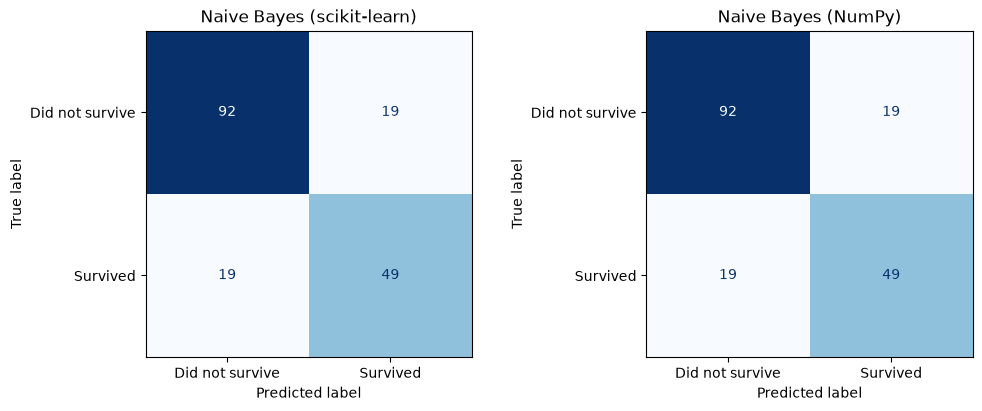

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (name, result) in zip(axes, evaluations.items()):
    ConfusionMatrixDisplay(np.array(result["confusion_matrix"]),
                           display_labels=["Did not survive", "Survived"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.savefig(GRAPHS / f"{file_stem}_confusion_matrix.png", dpi=150)
plt.show()
plt.close(fig)

## 7. Update the shared results

Keep results for both implementations of this model. Run both notebooks after changing preparation or training code.

In [7]:
metrics_path = OUTPUT / "metrics.json"
saved = json.loads(metrics_path.read_text()) if metrics_path.exists() else {}
for old_name in ["Naive Bayes", "Logistic Regression"]:
    saved.pop(old_name, None)
for name, result in evaluations.items():
    result["majority_baseline_accuracy"] = float(baseline_accuracy)
    result["implementation"] = "NumPy" if name.endswith("(NumPy)") else "scikit-learn"
    saved[name] = result
order = ["Naive Bayes (scikit-learn)", "Naive Bayes (NumPy)",
         "Logistic Regression (scikit-learn)", "Logistic Regression (NumPy)"]
saved = {name: saved[name] for name in order if name in saved}
metrics_path.write_text(json.dumps(saved, indent=2) + "\n")
lines = ["# Titanic model metrics", "",
         f"Training records: {len(y_train)}. Test records: {len(y_test)}. Positive class: survived (1).",
         "These are test results from models fitted on the training records.", "",
         "| Model / implementation | Accuracy | Precision | Recall | F1 | ROC-AUC | Log-loss |",
         "| --- | ---: | ---: | ---: | ---: | ---: | ---: |"]
for name, result in saved.items():
    values = result["metrics"]
    lines.append("| " + name + " | " + " | ".join(f"{values[key]:.6f}" for key in scores) + " |")
lines += ["", f"Majority-class baseline accuracy: {baseline_accuracy:.4f}.", "",
          "## Confusion matrices", ""]
for family, stem in [("Naive Bayes", "naive_bayes"), ("Logistic Regression", "logistic_regression")]:
    if any(name.startswith(family) for name in saved):
        lines += [f"![{family}: library and NumPy](graphs/{stem}_confusion_matrix.png)", ""]
lines += ["Rows are true labels; columns are predictions, ordered [0, 1].", "",
          "## Implementations", "",
          "The scikit-learn estimators remain as baselines. NumPy model training and prediction are implemented directly in each notebook.",
          "Naive Bayes estimates priors, class means/variances, Gaussian log-likelihoods and normalized probabilities.",
          "NumPy Logistic Regression minimizes mean binary cross-entropy plus ||w||^2/(2*C*n), with an unpenalized intercept.",
          "It uses full-batch gradient descent: C=1, learning rate 0.1, maximum 50,000 steps, gradient tolerance 1e-7.",
          "The library LR baseline uses C=1 with its default L-BFGS solver and max_iter=1000.",
          "Scikit-learn is still used for shared preparation, evaluation metrics and confusion-matrix display.", ""]
if "Logistic Regression (NumPy)" in saved:
    lines += ["![NumPy Logistic Regression training loss](graphs/logistic_regression_training_loss.png)", ""]
lines += ["## Findings", ""]
for family in ["Naive Bayes", "Logistic Regression"]:
    library, manual = family + " (scikit-learn)", family + " (NumPy)"
    if library in saved and manual in saved:
        reference, direct = saved[library]["metrics"], saved[manual]["metrics"]
        lines += [f"{family} accuracy: scikit-learn {reference['Accuracy']:.2%}, NumPy {direct['Accuracy']:.2%}.",
                  f"Log-loss: scikit-learn {reference['Log-loss']:.6f}, NumPy {direct['Log-loss']:.6f}.", ""]
lines += ["All implementations use the same fixed records and training-only preparation. Optimizer convergence is checked on training data; test scores are not used to choose settings.",
          "The test partition was inspected during earlier development; this is a fixed comparison, not a new independent test.",
          "A single historical sample does not establish that one model is universally better.", ""]
(OUTPUT / "metrics.md").write_text("\n".join(lines), encoding="utf-8")
print("Updated metrics.md and metrics.json with both implementations")

Updated metrics.md and metrics.json with both implementations
